In [ ]:
import sys
sys.path.insert(0,'C:/Users/mailt/GaPP3-main.zip/GaPP3-main/')
sys.path.insert(0,'C:/Users/mailt/GaPP3-main.zip/GaPP3-main/gapp/')
sys.path.insert(0,'C:/Users/mailt/GaPP3-main.zip/GaPP3-main/gapp/covfunctions/')

import covfunctions
from gapp import gp
from gapp import covariance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

In [ ]:
# DES observed data
des = pd.read_csv(
    r"File path from the data saved in your computer.csv"
)


# Hubble GP prediction
gpdata = pd.read_csv(
    r"File path from the data saved in your computer.csv"
)

In [ ]:
print(des.columns)
print(gpdata.columns)

Index(['zHD', 'MU', 'MUERR'], dtype='str')
Index(['z', 'mu', 'sigma_mu'], dtype='str')


In [ ]:
z_des = des["zHD"].to_numpy()

mu_des = des["MU"].to_numpy()

mu_des_err = des["MUERR"].to_numpy()

In [ ]:
z_gp = gpdata["z"].to_numpy()

mu_gp = gpdata["mu"].to_numpy()

mu_gp_err = gpdata["sigma_mu"].to_numpy()

In [ ]:
from scipy.interpolate import interp1d

# interpolate GP prediction onto DES redshifts
mu_interp = interp1d(
    z_gp,
    mu_gp,
    kind='linear',
    bounds_error=False,
    fill_value="extrapolate"
)

sigma_interp = interp1d(
    z_gp,
    mu_gp_err,
    kind='linear',
    bounds_error=False,
    fill_value="extrapolate"
)

mu_gp_at_des = mu_interp(z_des)
mu_gp_err_at_des = sigma_interp(z_des)

In [ ]:
# Keep only DES supernovae within the GP range
mask = z_des <= z_gp.max()

z_des = z_des[mask]
mu_des = mu_des[mask]
mu_des_err = mu_des_err[mask]

print(len(z_des))

847


In [ ]:
print(np.allclose(z_des, z_gp))

True


In [ ]:
delta_mu = mu_des - mu_gp

delta_mu_err = np.sqrt(
    mu_des_err**2 +
    mu_gp_err**2
)

In [ ]:
g1 = gp.GaussianProcess(
    z_des.reshape(-1,1),
    delta_mu,
    delta_mu_err,
    covfunction=covariance.SquaredExponential,
    Xstar=np.linspace(z_des.min(), z_des.max(), 300)
)

rec1, theta1 = g1.gp()


Optimized hyperparameters:
theta = [0.05345506 0.37874352]


In [ ]:
zrec = rec1[:,0]
gp_mean = rec1[:,1]
gp_sigma = rec1[:,2]

print(rec1.shape)

(300, 3)


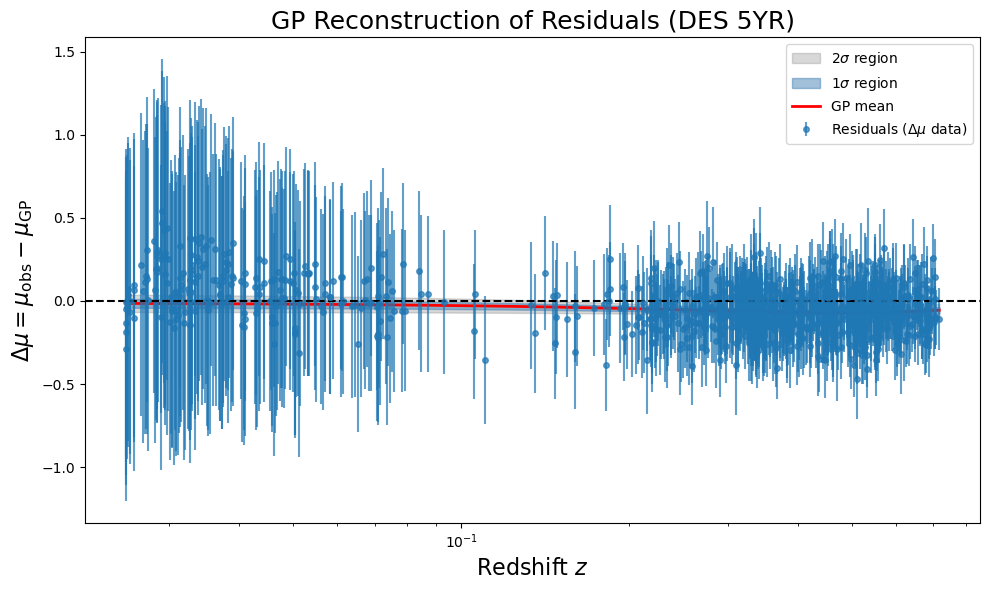

In [ ]:
plt.figure(figsize=(10,6))

# 2σ region
plt.fill_between(
    zrec,
    gp_mean-2*gp_sigma,
    gp_mean+2*gp_sigma,
    color="gray",
    alpha=0.30,
    label=r"2$\sigma$ region"
)

# 1σ region
plt.fill_between(
    zrec,
    gp_mean-gp_sigma,
    gp_mean+gp_sigma,
    color="steelblue",
    alpha=0.50,
    label=r"1$\sigma$ region"
)

# GP mean
plt.plot(
    zrec,
    gp_mean,
    color="red",
    lw=2,
    label="GP mean"
)

# Residual data
plt.errorbar(
    z_des,
    delta_mu,
    yerr=delta_mu_err,
    fmt='o',
    ms=4,
    color='tab:blue',
    alpha=0.70,
    label=r"Residuals ($\Delta\mu$ data)"
)

plt.axhline(
    0,
    color='black',
    linestyle='--'
)

plt.xscale("log")

plt.xlabel("Redshift $z$", fontsize=16)

plt.ylabel(r"$\Delta\mu=\mu_{\rm obs}-\mu_{\rm GP}$", fontsize=16)

plt.title("GP Reconstruction of Residuals (DES 5YR)", fontsize=18)

plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
results = pd.DataFrame({
    "z": zrec,
    "delta_mu_GP": gp_mean,
    "sigma_GP": gp_sigma
})

results.to_csv(
    "DES_Residual_GP_Reconstruction.csv",
    index=False
)

In [ ]:
import numpy as np
import pandas as pd


In [ ]:
pantheon = pd.read_csv(
    r"C:\DARK ENERGY DESI DR2 datasets\Pantheon+SH0ES.csv",
    sep=r"\s+")

z_obs = pantheon["zHD"].to_numpy()
mu_obs = pantheon["MU_SH0ES"].to_numpy()
mu_obs_err = pantheon["MU_SH0ES_ERR_DIAG"].to_numpy()

In [ ]:
gpdata = pd.read_csv(
    r"C:\DARK ENERGY DESI DR2 datasets\Pantheon dist from Hubble GP.csv"
)

z_gp = gpdata["z"].to_numpy()
mu_gp = gpdata["mu"].to_numpy()
mu_gp_err = gpdata["sigma_mu"].to_numpy()

In [ ]:
print("OBS:", z_obs.shape, mu_obs.shape, mu_obs_err.shape)
print("GP :", z_gp.shape, mu_gp.shape, mu_gp_err.shape)

OBS: (1701,) (1701,) (1701,)
GP : (1700,) (1700,) (1700,)


In [ ]:
valid = (
    np.isfinite(z_gp) &
    np.isfinite(mu_gp) &
    np.isfinite(mu_gp_err) &
    np.isfinite(mu_obs_matched) &
    np.isfinite(mu_obs_err_matched)
)

print("Total matched points:", len(valid))
print("Valid points:", np.sum(valid))
print("Invalid points:", np.sum(~valid))

print("\nInvalid redshifts:")
print(z_gp[~valid])

Total matched points: 1700
Valid points: 1671
Invalid points: 29

Invalid redshifts:
[0.00122 0.00122 0.00256 0.00256 0.00299 0.00317 0.00331 0.00331 0.00331
 0.00331 0.00333 0.00349 0.00349 0.00359 0.00384 0.00407 0.00407 0.00432
 0.00432 0.00465 0.00465 0.00482 0.00483 0.00483 0.00483 0.00483 0.00483
 0.00488 0.00488]


In [ ]:
# Keep only points where both observational and GP quantities are finite

z_clean = z_gp[valid]

mu_obs_clean = mu_obs_matched[valid]
mu_obs_err_clean = mu_obs_err_matched[valid]

mu_gp_clean = mu_gp[valid]
mu_gp_err_clean = mu_gp_err[valid]

print("Number of clean points:", len(z_clean))
print("Redshift range:", z_clean.min(), "to", z_clean.max())

Number of clean points: 1671
Redshift range: 0.00538 to 1.91165


In [ ]:
# Residual:

delta_mu = mu_obs_clean - mu_gp_clean


# Propagated residual uncertainty:
# σ_Δμ = sqrt(σ_obs² + σ_GP²)

delta_mu_err = np.sqrt(
    mu_obs_err_clean**2 +
    mu_gp_err_clean**2
)


# Final checks
print("Number of residuals:", len(delta_mu))
print("All residuals finite:", np.all(np.isfinite(delta_mu)))
print("All uncertainties finite:", np.all(np.isfinite(delta_mu_err)))

print("\nResidual range:")
print(delta_mu.min(), delta_mu.max())

Number of residuals: 1671
All residuals finite: True
All uncertainties finite: True

Residual range:
-0.8349197665724795 1.724359107360872


In [ ]:
# Prediction grid for the GP reconstruction

zstar = np.logspace(
    np.log10(z_clean.min()),
    np.log10(z_clean.max()),
    300
)


g_pantheon = gp.GaussianProcess(
    z_clean,
    delta_mu,
    delta_mu_err,
    covfunction=covariance.SquaredExponential,
    Xstar=zstar,
    thetatrain=True
)


rec_pantheon, theta_pantheon = g_pantheon.gp()


Optimized hyperparameters:
theta = [0.1361061  0.55652913]


In [ ]:
print("Optimized hyperparameters:")
print(theta_pantheon)

print("\nReconstruction shape:")
print(rec_pantheon.shape)

print("\nFirst five reconstructed points:")
print(rec_pantheon[:5])

Optimized hyperparameters:
[0.1361061  0.55652913]

Reconstruction shape:
(300, 3)

First five reconstructed points:
[[ 0.00538    -0.04159234  0.02558559]
 [ 0.00548672 -0.04163535  0.02557419]
 [ 0.00559556 -0.04167921  0.02556256]
 [ 0.00570655 -0.04172395  0.02555071]
 [ 0.00581975 -0.04176957  0.02553863]]


In [ ]:
z_rec = rec_pantheon[:, 0]
gp_mean = rec_pantheon[:, 1]
gp_sigma = rec_pantheon[:, 2]

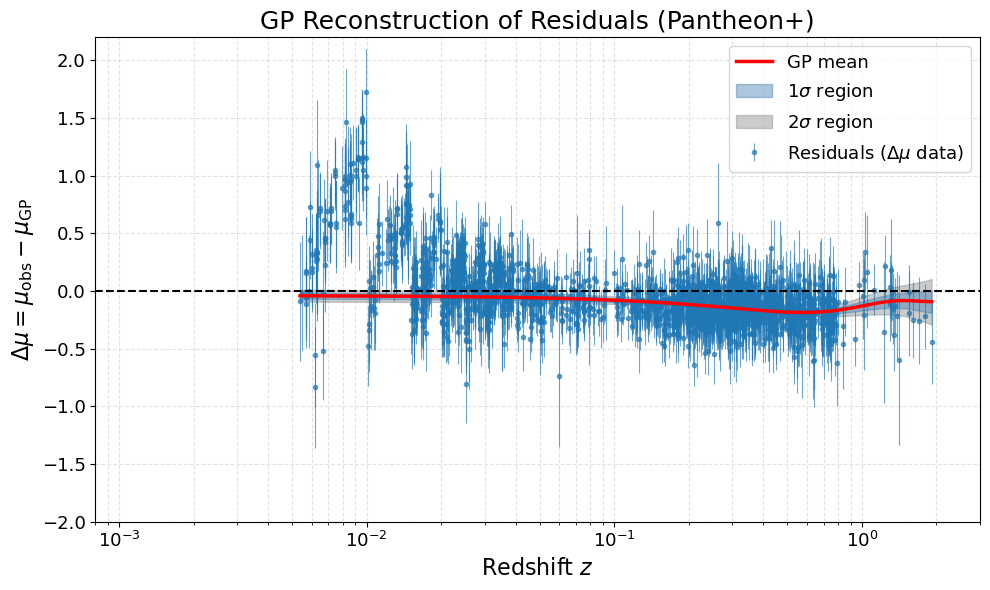

In [ ]:
plt.figure(figsize=(10, 6))

# 2 sigma region
plt.fill_between(
    z_rec,
    gp_mean - 2 * gp_sigma,
    gp_mean + 2 * gp_sigma,
    color="gray",
    alpha=0.4,
    label=r"2$\sigma$ region",
    zorder=1)

# 1 sigma region
plt.fill_between(
    z_rec,
    gp_mean - gp_sigma,
    gp_mean + gp_sigma,
    color="steelblue",
    alpha=0.45,
    label=r"1$\sigma$ region",
    zorder=2)

# Residual data
plt.errorbar(
    z_clean,
    delta_mu,
    yerr=mu_obs_err_clean,
    fmt="o",
    markersize=3,
    color="tab:blue",
    ecolor="tab:blue",
    alpha=0.65,
    elinewidth=0.8,
    capsize=0,
    label=r"Residuals ($\Delta\mu$ data)",
    zorder=3)

# GP mean
plt.plot(
    z_rec,
    gp_mean,
    color="red",
    linewidth=2.5,
    label="GP mean",
    zorder=4)

# Zero-residual reference line
plt.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    zorder=5)

# Logarithmic redshift axis
plt.xscale("log")

# Match the target figure
plt.xlim(8e-4, 3)
plt.ylim(-2.0, 2.2)

plt.xlabel(r"Redshift $z$", fontsize=16)
plt.ylabel(
    r"$\Delta\mu = \mu_{\rm obs} - \mu_{\rm GP}$",
    fontsize=16)

plt.title(
    "GP Reconstruction of Residuals (Pantheon+)",
    fontsize=18)

plt.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.35)

# Put legend entries in the same order as the target figure
handles, labels = plt.gca().get_legend_handles_labels()

order = [labels.index("GP mean"),
    labels.index(r"1$\sigma$ region"),
    labels.index(r"2$\sigma$ region"),
    labels.index(r"Residuals ($\Delta\mu$ data)")]

plt.legend([handles[i] for i in order],[labels[i] for i in order],fontsize=13,loc="upper right")

plt.tick_params(axis="both",labelsize=13)

plt.tight_layout()
plt.show()

In [ ]:
print(pantheon.columns.tolist())

['CID', 'IDSURVEY', 'zHD', 'zHDERR', 'zCMB', 'zCMBERR', 'zHEL', 'zHELERR', 'm_b_corr', 'm_b_corr_err_DIAG', 'MU_SH0ES', 'MU_SH0ES_ERR_DIAG', 'CEPH_DIST', 'IS_CALIBRATOR', 'USED_IN_SH0ES_HF', 'c', 'cERR', 'x1', 'x1ERR', 'mB', 'mBERR', 'x0', 'x0ERR', 'COV_x1_c', 'COV_x1_x0', 'COV_c_x0', 'RA', 'DEC', 'HOST_RA', 'HOST_DEC', 'HOST_ANGSEP', 'VPEC', 'VPECERR', 'MWEBV', 'HOST_LOGMASS', 'HOST_LOGMASS_ERR', 'PKMJD', 'PKMJDERR', 'NDOF', 'FITCHI2', 'FITPROB', 'm_b_corr_err_RAW', 'm_b_corr_err_VPEC', 'biasCor_m_b', 'biasCorErr_m_b', 'biasCor_m_b_COVSCALE', 'biasCor_m_b_COVADD']
